# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [5]:
bounds

2-element Vector{Vector{Float64}}:
 [0.9200000000000017, 51.23, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [80.92, 51.23, 0.027499999999999997, 0.1375, 0.22499999999999998, 2.0, 2.0, 2.0, 2.0, 0.0425, 2.0, 0.014499999999999999]

# Extract Experimental Data 3.2 mM

In [8]:
# mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
mainpath = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";

i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv"];
conce = [3.2];

In [9]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Dict{String, Any} with 15 entries:
  "Means"  => [9177.49; 6162.55; … ; -6.00262; 5.56735;;; 0.0; 34.6837; … ; -0.…
  "stsl"   => [77;;]
  "obSta"  => [1 2]
  "sts"    => [0; 20; … ; 390; 395;;]
  "obser"  => 2
  "Y0us"   => [3200.0; 0.0; … ; 0.0; 9177.49;;]
  "ts"     => [1.0e-20; 1.0; … ; 394.0; 395.0;;]
  "itp"    => [0.0]
  "ScFms"  => [23.8997;;]
  "ncells" => [4;;]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947; 491.932; … ; 7.38584; 6.8147;;; 1.0; 4.36114; … ; 6.420…
  "m"      => 1
  "nts"    => [395;;]

In [15]:
priorInfer = hcat(sampsTh,sampsY0)
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];
CompRepUtil_Entro_OEDmc(conce)

349.1749112520019

# Simulate Experiment Prior Prediction

In [9]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][1];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"];
    ts = 0:tsC2[end];
    ivss = [round(conce[1], digits = 1)*1000, 0, 0, sampsY0[i,1], sampsY0[i,1], sampsY0[i,1], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(sampsTh[i,1:end], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [10]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


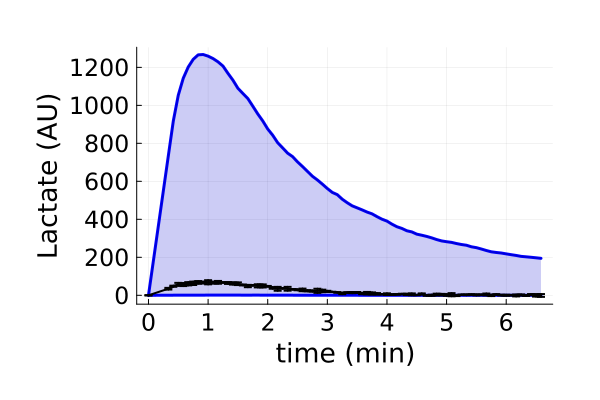

In [11]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

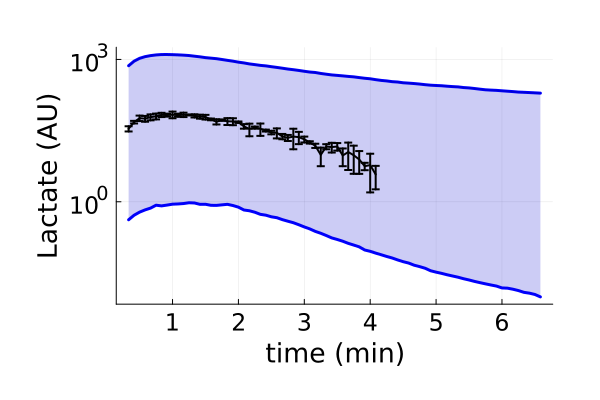

In [12]:
pr = plot(tsC2[2:end]./60, PriorQuant[1][2:end], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2[2:end]./60, PriorQuant[2][2:end], label = "", color = "blue", linewidth = 3)
  plot!(tsC2[2:end]./60, PriorQuant[1][2:end], fillrange=PriorQuant[2][2:end], label="", color="blue3", fillalpha=0.2, yaxis=:log)

  plot!(dat["sts"][2:end-30]./60, dat["Means"][:,1,2][2:end-30], yerror = dat["Erros"][:,1,2][2:end-30], linewidth = 2, colour = "black", label = "", yaxis=:log)

  
display(pr)

# MLE to obtain a good first guess for inference

In [13]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    pD2 = vcat(p[1:end-3], dat["ScFms"][1], 0);
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        # Define time vector
        t2cor = dat["sts"][:,i];

        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));

        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        obj = -(mm22)+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [14]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

1812.4931478091114

In [15]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*2, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.62 secs, 111 evals, 61 steps, improv/step: 0.443 (last = 0.4426), fitness=287.158434889
1.13 secs, 248 evals, 154 steps, improv/step: 0.390 (last = 0.3548), fitness=251.852517996
1.64 secs, 357 evals, 245 steps, improv/step: 0.380 (last = 0.3626), fitness=251.852517996
2.14 secs, 464 evals, 340 steps, improv/step: 0.341 (last = 0.2421), fitness=249.343982108
2.70 secs, 589 evals, 452 steps, improv/step: 0.314 (last = 0.2321), fitness=249.343982108
3.20 secs, 729 evals, 587 steps, improv/step: 0.284 (last = 0.1852), fitness=231.806988516
3.70 secs, 844 evals, 697 steps, improv/step: 0.270 (last = 0.1909), fitness=223.124448965
4.20 secs, 955 evals, 805 steps, improv/step: 0.256 (last = 0.1667), fitness=214.237894425
4.71 secs, 1105 evals, 954 steps, improv/step: 0.233 (last = 0.1074),

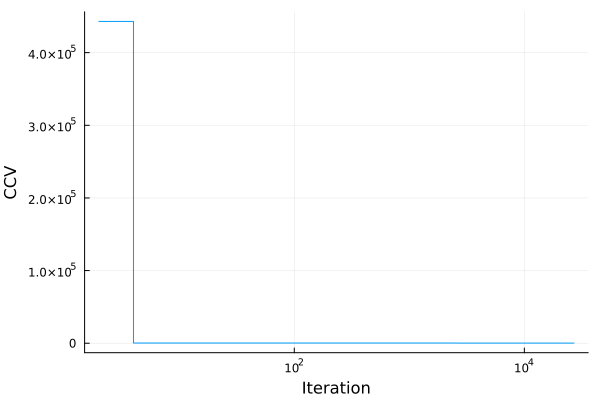

In [16]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [17]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    31.12125208897105
    51.23
     0.004151714857533111
     0.03084455137346202
     0.02449690604365438
     1.1771889139922322
     0.9921792367932667
     0.5645714380971351
     1.481761424209396
     0.042160156622038834
     0.6122899357331061
     0.013449660435598093
   113.39830814440796
 13458.347381535152
  1373.1151533951336

In [18]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_Init.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_Init.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#83#84".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [19]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_Init.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    31.12125208897105
    51.23
     0.004151714857533111
     0.03084455137346202
     0.02449690604365438
     1.1771889139922322
     0.9921792367932667
     0.5645714380971351
     1.481761424209396
     0.042160156622038834
     0.6122899357331061
     0.013449660435598093
   113.39830814440796
 13458.347381535152
  1373.1151533951336

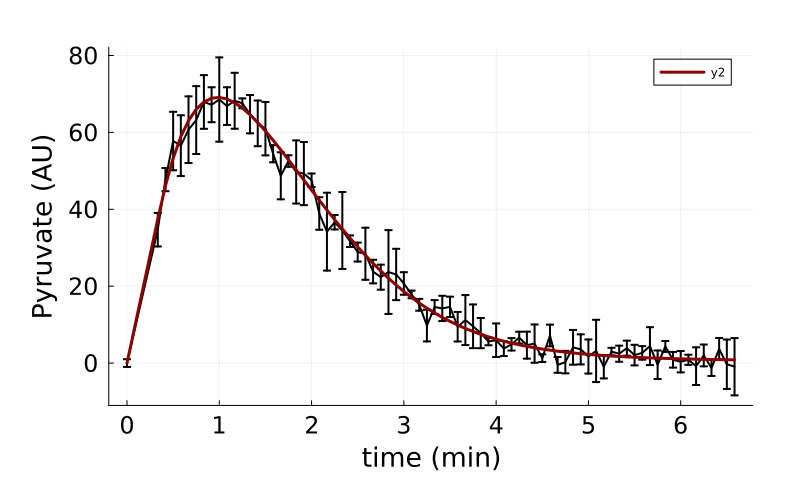

In [20]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")

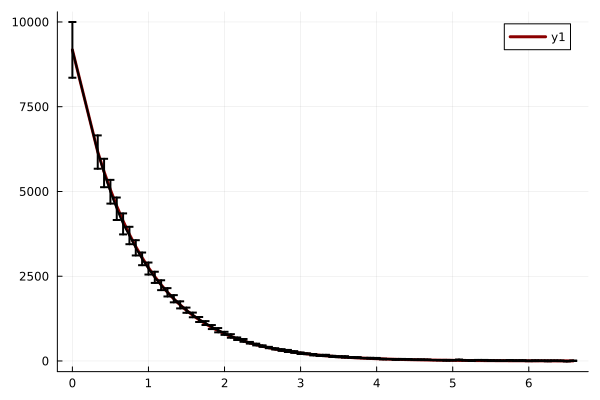

In [21]:
plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Compute structure for Stan's initial guess

In [22]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [23]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 3.9600184261222156, "LDH" => 2.99314601234594, "kin" => -0.2451427531757979, "ki" => -0.3554842781756778, "kunE" => 0.5597488675888379, "kpl" => 0.12162004994407344, "NADH" => -2.063852660983046, "kup" => -0.40571427568722623, "T1_X" => -0.9798747911028951, "kbp" => 0.04439919662449131…)
 Dict("kbnE" => 3.9600184261222156, "LDH" => 2.99314601234594, "kin" => -0.2451427531757979, "ki" => -0.3554842781756778, "kunE" => 0.5597488675888379, "kpl" => 0.12162004994407344, "NADH" => -2.063852660983046, "kup" => -0.40571427568722623, "T1_X" => -0.9798747911028951, "kbp" => 0.04439919662449131…)
 Dict("kbnE" => 3.9600184261222156, "LDH" => 2.99314601234594, "kin" => -0.2451427531757979, "ki" => -0.3554842781756778, "kunE" => 0.5597488675888379, "kpl" => 0.12162004994407344, "NADH" => -2.063852660983046, "kup" => -0.40571427568722623, "T1_X" => -0.9798747911028951, "kbp" => 0.04439919662449131…)
 Dict("kbnE" => 3.9600184261222156, "LDH" => 2.9

In [24]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 3.96002
  "LDH"  => 2.99315
  "kin"  => -0.245143
  "ki"   => -0.355484
  "kunE" => 0.559749
  "kpl"  => 0.12162
  "NADH" => -2.06385
  "kup"  => -0.405714
  "T1_X" => -0.979875
  "kbp"  => 0.0443992
  "kr"   => 3.63781
  "NAD"  => -0.397133
  "kun"  => 1.61598
  "kbn"  => -0.455624

# Inference

In [25]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Init_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 400, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;


File d:\David\BayesianInferencesInVivoScripts\ExperimentalBayesianOED\tmp\PyrCompRepr_Init_Try1.stan will be updated.



In [26]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Init_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(400,400,400,400,400,400,400,400,400,400); thin=(1,1,1,1,1,1,1,1,1,1); 12000 iterations saved.

Warmup took (26170, 25572, 25884, 23103, 27217, 25228, 26021, 23360, 26617, 26290) seconds, 71 hours total
Sampling took (69170, 52851, 56022, 48120, 62116, 72504, 65487, 67730, 52112, 63919) seconds, 169 hours total

                    Mean     MCSE   StdDev        5%       50%      95%    N_Eff  N_Eff/s    R_hat

lp__            -2.0e+02  6.2e-02  3.0e+00  -2.1e+02  -2.0e+02 -2.0e+02  2.4e+03  4.0e-03  1.0e+00
accept_stat__    9.5e-01  1.1e-02  1.2e-01   7.6e-01   9.9e-01  1.0e+00  1.1e+02  1.8e-04  1.0e+00
stepsize__       5.7e-03  4.4e-04  1.9e-03   2.8e-03   5.5e-03  9.3e-03  1.9e+01  3.1e-05  1.2e+00
treedepth__      9.2e+00  1.2e-01  7.5e-01   8.0e+00   9.0e+00  1.0e+01  4.0e+01  6.5e-05  1.1e+00
n_leapfrog__     7.2e+02  4.1e+01  2.8e+02   2.6e+02   5.1e+

(0, [-215.353 0.998502 … 15765.4 138.507; -215.353 0.0 … 15765.4 138.507; … ; -204.146 0.995528 … 16344.7 636.429; -202.297 0.962619 … 15731.6 565.679;;; -211.405 0.704626 … 20821.6 174.938; -211.405 0.0 … 20821.6 174.938; … ; -200.765 0.907431 … 13104.3 550.618; -199.141 0.988522 … 21051.8 674.718;;; -207.906 0.990211 … 25223.5 187.252; -207.906 0.0 … 25223.5 187.252; … ; -201.12 0.972765 … 19063.8 564.245; -204.515 0.951107 … 13852.1 527.811;;; -203.647 0.996702 … 19524.2 1388.56; -203.647 0.0 … 19524.2 1388.56; … ; -200.68 0.615835 … 21586.4 447.004; -207.326 0.923865 … 19776.8 408.282;;; -209.549 0.939667 … 24781.9 358.789; -209.549 0.0 … 24781.9 358.789; … ; -202.966 0.905524 … 7272.31 640.812; -203.02 0.997044 … 8102.69 664.69;;; -215.482 0.389727 … 12657.3 427.93; -215.482 0.0 … 12657.3 427.93; … ; -204.845 0.987335 … 16001.0 702.786; -206.055 0.999534 … 7165.59 955.738;;; -201.938 0.938652 … 16661.0 1265.21; -201.938 0.0 … 16661.0 1265.21; … ; -203.264 0.887803 … 11262.3 570.47

In [37]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_Init_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [38]:
poster = vcat(chns[401:end, end-15:end, 1], chns[401:end, end-15:end, 2], chns[401:end, end-15:end, 3], chns[401:end, end-15:end, 4], chns[401:end, end-15:end, 5], 
              chns[401:end, end-15:end, 6], chns[401:end, end-15:end, 7], chns[401:end, end-15:end, 8], chns[401:end, end-15:end, 9], chns[401:end, end-15:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv"

In [39]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 41.1949  51.23  0.00772956  0.0186012  …  108.217   29811.1    503.579
 51.6101  51.23  0.00555101  0.0274524      92.1469  26464.8    606.874
 35.1197  51.23  0.00359025  0.022186       99.0307  24812.1   1052.16
 42.6028  51.23  0.00456304  0.0212256      85.5154  19561.7    687.445
 47.9692  51.23  0.00240846  0.0221916     728.696   19468.1     96.2662
 34.1855  51.23  0.00208756  0.0264356  …  966.98    13295.4     51.994
 41.3952  51.23  0.00365566  0.0360747     674.542   13456.3     34.8437
 43.0616  51.23  0.00375345  0.0534735     913.116   13598.4     19.7182
 40.0763  51.23  0.00456141  0.0192255     623.161    8511.54    89.1608
 38.109   51.23  0.00208587  0.0394897     793.988   24283.8     29.0393
  ⋮                                     ⋱                         ⋮
 49.7357  51.23  0.00225835  0.0386458      64.7826  17986.2    729.165
 30.5304  51.23  0.00610859  0.0242321     830.675   16655.5    477.217
 50.8069  51.23  0.00687396  0.02793   

# Plot Posterior VS Prior

In [40]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [41]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

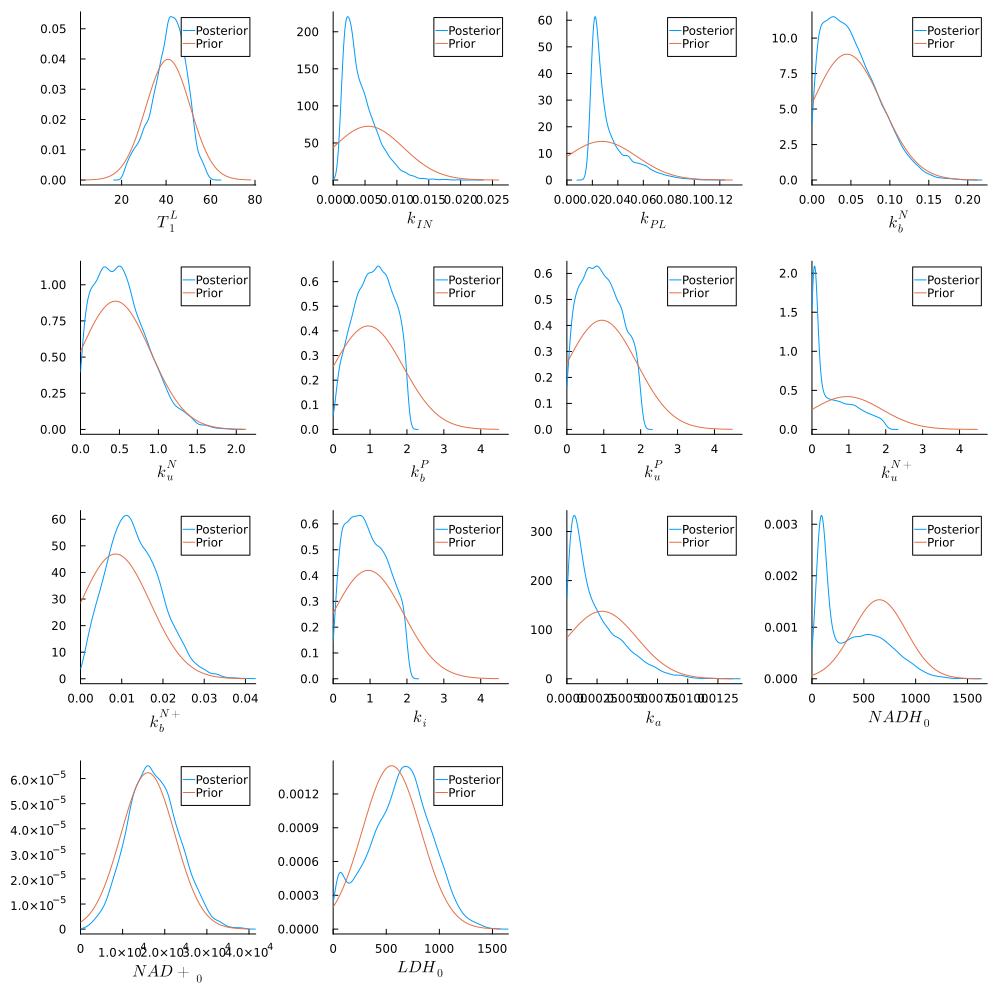

In [42]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [43]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

14.761973014630014

In [47]:
using CairoMakie
using PairPlots
using DataFrames

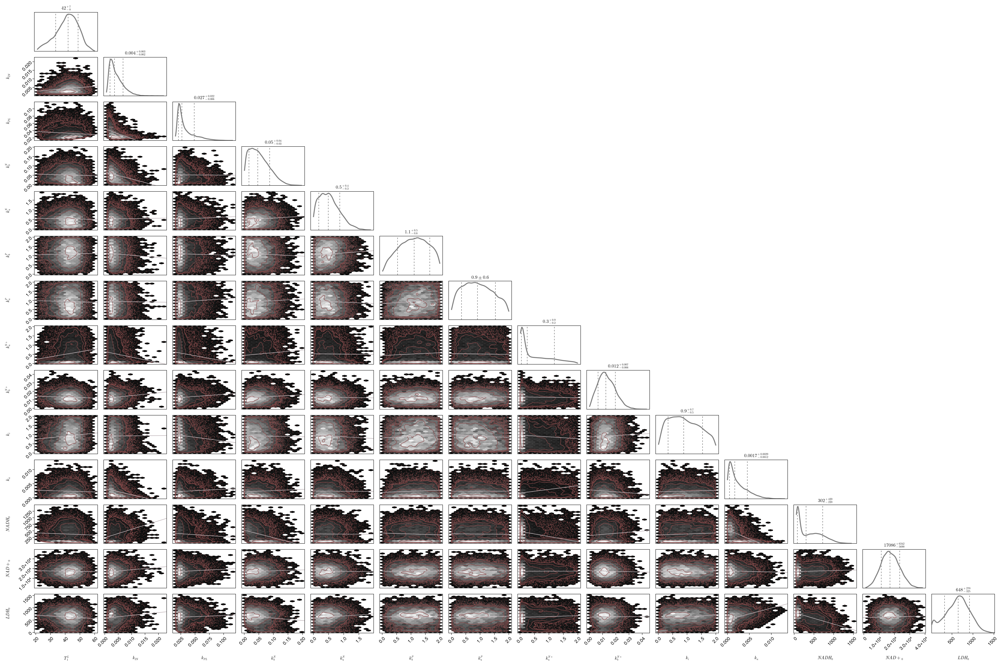

In [50]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

## Experiment 1

In [1]:
simsPoster = Array{Any}(undef, 8000);


for i in 1:8000
    tsC2 = dat["sts"][:,1];
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,1,1]/(sampsTh[i,end]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,1,1]/(sampsTh[i,end]*0.12), 0, dat["Means"][1,1,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:13], 0), ivss, samps);

    simsPoster[i] = SimulsAll;
end

UndefVarError: UndefVarError: `dat` not defined

In [52]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,1);
lacPostSims = zeros(size(simsPoster[1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end


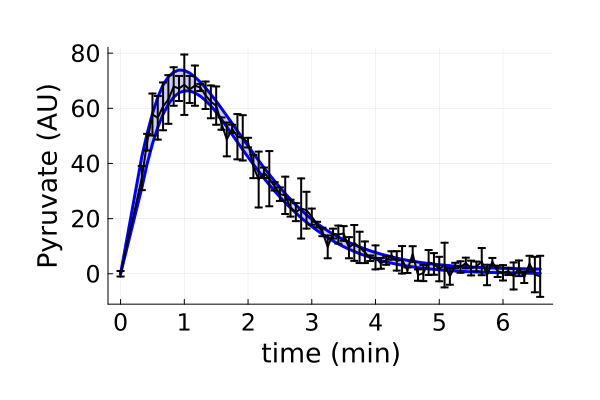

In [53]:
pr = plot(tsC2./60, PostQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1], fillrange=PostQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

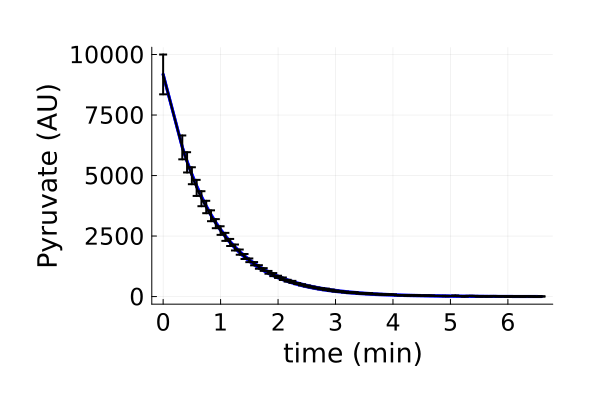

In [54]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,1);
pyrPostSims = zeros(size(simsPoster[1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1], fillrange=PostQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")